<a href="https://colab.research.google.com/github/sylviadu2552/DATA4401---Project-3/blob/main/Project3_n_grams.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
from pathlib import Path
import pandas as pd

# Download latest version
path = Path(kagglehub.dataset_download("zynicide/wine-reviews"))
INPUT_FILE = path / "winemag-data-130k-v2.csv"

print("Dataset directory:", path)
print("Path to dataset file:", INPUT_FILE)

wines = pd.read_csv(INPUT_FILE, index_col=0)

print("Dataset shape:", wines.shape)
display(wines.head())

Using Colab cache for faster access to the 'wine-reviews' dataset.
Dataset directory: /kaggle/input/wine-reviews
Path to dataset file: /kaggle/input/wine-reviews/winemag-data-130k-v2.csv
Dataset shape: (129971, 13)


,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [2]:
data = wines[["taster_name", "description"]].dropna().copy()
data["description"] = data["description"].astype(str).str.strip()
data = data[data["description"] != ""]

# Normalize case and whitespace only for duplicate detection
data["_text_key"] = (
    data["description"]
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Exclude identical wording assigned to multiple reviewers
reviewer_count_per_text = data.groupby("_text_key")["taster_name"].transform("nunique")
data = data[reviewer_count_per_text == 1]

# Keep one instance of each review
data = data.drop_duplicates(subset="_text_key")

# Keep reviewers with at least 100 unique reviews
reviewer_counts = data["taster_name"].value_counts()
eligible_reviewers = reviewer_counts[reviewer_counts >= 100].index
data = data[data["taster_name"].isin(eligible_reviewers)].copy()

print("Reviewers included:", len(eligible_reviewers))
print("Unique reviews used:", len(data))
display(data["taster_name"].value_counts().rename("reviews"))

Reviewers included: 17
Unique reviews used: 95011


,reviews
taster_name,
Roger Voss,23558
Michael Schachner,14045
Kerin O’Keefe,9679
Paul Gregutt,8867
Virginie Boone,8707
Matt Kettmann,5729
Joe Czerwinski,4763
Sean P. Sullivan,4460
Anna Lee C. Iijima,4017


In [3]:
from sklearn.model_selection import train_test_split

# Hold out test data for the final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    data["description"],
    data["taster_name"],
    test_size=0.2,
    random_state=42,
    stratify=data["taster_name"]
)

# Set aside validation data from the training split for early stopping
X_fit_text, X_val_text, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=43,
    stratify=y_train
)

print("Fit reviews:", len(X_fit_text))
print("Validation reviews:", len(X_val_text))
print("Test reviews:", len(X_test))

Fit reviews: 64606
Validation reviews: 11402
Test reviews: 19003


In [27]:
import re
from collections import Counter

import numpy as np
import torch
import torch.nn.functional as F

from torch import nn
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

function_words = [
    "a", "an", "the", "and", "or", "but", "if", "of", "to", "in",
    "on", "at", "by", "for", "with", "from", "as", "is", "are",
    "was", "were", "be", "it", "this", "that", "which", "very", "not"
]
punctuation_marks = [",", ".", ";", ":", "!", "?", "—", "-", "(", ")", '"']

word_pattern = re.compile(r"\b[\w']+\b")
sentence_pattern = re.compile(r"[.!?]+")
punctuation_pattern = re.compile(r'[,.;:!?—()"\-]')

def style_features(text):
    text = str(text)
    words = word_pattern.findall(text.casefold())
    word_counts = Counter(words)
    sentences = [
        sentence for sentence in sentence_pattern.split(text)
        if sentence.strip()
    ]
    punctuation_counts = Counter(punctuation_pattern.findall(text))

    word_count = max(len(words), 1)
    sentence_count = max(len(sentences), 1)

    if words:
        lengths = np.fromiter((len(word) for word in words), dtype=np.float32)
        mean_word_length = float(lengths.mean())
        std_word_length = float(lengths.std())
    else:
        mean_word_length = 0.0
        std_word_length = 0.0

    features = [
        np.log1p(len(text)),
        np.log1p(len(words)),
        mean_word_length,
        std_word_length,
        sentence_count / word_count,
        word_count / sentence_count,
    ]

    features.extend(word_counts[word] / word_count for word in function_words)
    features.extend(
        punctuation_counts[mark] * 100 / word_count
        for mark in punctuation_marks
    )

    return features

def make_feature_matrices(train_text, eval_text):
    train_text = list(train_text)
    eval_text = list(eval_text)

    vectorizer = TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=5,
        max_features=20_000,
        lowercase=False,
        dtype=np.float32
    )

    train_char = vectorizer.fit_transform(train_text)
    eval_char = vectorizer.transform(eval_text)

    train_style_raw = np.asarray(
        [style_features(text) for text in train_text],
        dtype=np.float32
    )
    eval_style_raw = np.asarray(
        [style_features(text) for text in eval_text],
        dtype=np.float32
    )

    scaler = StandardScaler()
    train_style = scaler.fit_transform(train_style_raw).astype(
        np.float32, copy=False
    )
    eval_style = scaler.transform(eval_style_raw).astype(
        np.float32, copy=False
    )

    train_features = hstack(
        [train_char, csr_matrix(train_style)],
        format="csr"
    ).astype(np.float32, copy=False)

    eval_features = hstack(
        [eval_char, csr_matrix(eval_style)],
        format="csr"
    ).astype(np.float32, copy=False)

    return train_features, eval_features

def to_torch_csr(matrix):
    matrix = matrix.tocsr(copy=False).astype(np.float32, copy=False)

    crow_indices = torch.from_numpy(
        np.asarray(matrix.indptr, dtype=np.int64)
    ).to(device)
    col_indices = torch.from_numpy(
        np.asarray(matrix.indices, dtype=np.int64)
    ).to(device)
    values = torch.from_numpy(
        np.asarray(matrix.data, dtype=np.float32)
    ).to(device)

    return torch.sparse_csr_tensor(
        crow_indices,
        col_indices,
        values,
        size=matrix.shape,
        device=device
    )

class SparseLinearReviewer(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.weight = nn.Parameter(
            torch.empty(n_features, n_classes, device=device)
        )
        self.bias = nn.Parameter(torch.zeros(n_classes, device=device))
        nn.init.xavier_uniform_(self.weight)

    def forward(self, x):
        return torch.sparse.mm(x, self.weight) + self.bias

def soft_macro_f1(logits, targets):
    probabilities = torch.softmax(logits, dim=1)
    true_positives = (probabilities * targets).sum(dim=0)
    predicted_positives = probabilities.sum(dim=0)
    actual_positives = targets.sum(dim=0)

    reviewer_f1 = (
        2 * true_positives
        / (predicted_positives + actual_positives + 1e-8)
    )

    return reviewer_f1.mean()

Using: cuda


In [28]:
label_encoder = LabelEncoder().fit(y_train)
n_classes = len(label_encoder.classes_)

max_epochs = 250
patience = 20
min_improvement = 1e-4

def find_best_epoch(X_fit, y_fit, X_val, y_val, seed):
    X_fit_torch = to_torch_csr(X_fit)
    X_val_torch = to_torch_csr(X_val)

    y_fit_ids = label_encoder.transform(y_fit)
    y_val_ids = label_encoder.transform(y_val)

    y_fit_torch = torch.tensor(y_fit_ids, dtype=torch.long, device=device)
    y_val_torch = torch.tensor(y_val_ids, dtype=torch.long, device=device)

    fit_targets = F.one_hot(y_fit_torch, num_classes=n_classes).float()
    val_targets = F.one_hot(y_val_torch, num_classes=n_classes).float()

    torch.manual_seed(seed)
    model = SparseLinearReviewer(X_fit.shape[1], n_classes)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.03)

    best_val_f1 = -float("inf")
    best_epoch = 1
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)

        fit_logits = model(X_fit_torch)
        loss = 1 - soft_macro_f1(fit_logits, fit_targets)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_torch)
            val_f1 = soft_macro_f1(val_logits, val_targets).item()

        if val_f1 > best_val_f1 + min_improvement:
            best_val_f1 = val_f1
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    return best_epoch, best_val_f1


# Estimate a good epoch count across three stratified folds
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
fold_best_epochs = []

for fold, (fit_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    fold_X_fit = X_train.iloc[fit_idx]
    fold_X_val = X_train.iloc[val_idx]
    fold_y_fit = y_train.iloc[fit_idx]
    fold_y_val = y_train.iloc[val_idx]

    X_fit_fold, X_val_fold = make_feature_matrices(
        fold_X_fit,
        fold_X_val
    )

    best_epoch, best_val_f1 = find_best_epoch(
        X_fit_fold,
        fold_y_fit,
        X_val_fold,
        fold_y_val,
        seed=42 + fold
    )

    fold_best_epochs.append(best_epoch)
    print(
        f"Fold {fold}: best epoch={best_epoch}, "
        f"validation soft macro-F1={best_val_f1:.4f}"
    )

chosen_epochs = max(1, int(round(np.median(fold_best_epochs))))
print("Epochs selected by cross-validation:", chosen_epochs)

# Refit features on all training reviews, then train for the selected epochs
X_fit_final, X_test_final = make_feature_matrices(X_train, X_test)
X_fit_torch = to_torch_csr(X_fit_final)
X_test_torch = to_torch_csr(X_test_final)

y_fit_ids = label_encoder.transform(y_train)
y_fit_torch = torch.tensor(y_fit_ids, dtype=torch.long, device=device)
fit_targets = F.one_hot(y_fit_torch, num_classes=n_classes).float()

torch.manual_seed(42)
model = SparseLinearReviewer(X_fit_final.shape[1], n_classes)
optimizer = torch.optim.Adam(model.parameters(), lr=0.03)

for epoch in range(1, chosen_epochs + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    fit_logits = model(X_fit_torch)
    loss = 1 - soft_macro_f1(fit_logits, fit_targets)
    loss.backward()
    optimizer.step()

    if epoch == 1 or epoch % 10 == 0 or epoch == chosen_epochs:
        print(
            f"Final fit epoch {epoch:03d}/{chosen_epochs} | "
            f"soft macro-F1 loss: {loss.item():.4f}"
        )

# Keep these names for existing evaluation cell
weights = model.weight
bias = model.bias

Fold 1: best epoch=69, validation soft macro-F1=0.9034
Fold 2: best epoch=88, validation soft macro-F1=0.9103
Fold 3: best epoch=105, validation soft macro-F1=0.9063
Epochs selected by cross-validation: 88
Final fit epoch 001/88 | soft macro-F1 loss: 0.9543
Final fit epoch 010/88 | soft macro-F1 loss: 0.4163
Final fit epoch 020/88 | soft macro-F1 loss: 0.1718
Final fit epoch 030/88 | soft macro-F1 loss: 0.0822
Final fit epoch 040/88 | soft macro-F1 loss: 0.0511
Final fit epoch 050/88 | soft macro-F1 loss: 0.0357
Final fit epoch 060/88 | soft macro-F1 loss: 0.0268
Final fit epoch 070/88 | soft macro-F1 loss: 0.0210
Final fit epoch 080/88 | soft macro-F1 loss: 0.0175
Final fit epoch 088/88 | soft macro-F1 loss: 0.0155


In [29]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

with torch.no_grad():
    test_logits = torch.sparse.mm(X_test_torch, weights) + bias
    predicted_ids = test_logits.argmax(dim=1).cpu().numpy()

predicted_reviewers = label_encoder.inverse_transform(predicted_ids)

# Per-reviewer metrics
report = pd.DataFrame(
    classification_report(
        y_test,
        predicted_reviewers,
        output_dict=True,
        zero_division=0
    )
).T

by_reviewer = report.drop(
    index=["accuracy", "macro avg", "weighted avg"],
    errors="ignore"
).copy()

# Accuracy and weighted F1 are overall metrics, so leave them blank for individual reviewers
by_reviewer["accuracy"] = np.nan
by_reviewer["weighted_f1"] = np.nan

# Add one Overall row
overall = pd.DataFrame(
    [{
        "precision": report.loc["macro avg", "precision"],
        "recall": report.loc["macro avg", "recall"],
        "f1-score": f1_score(y_test, predicted_reviewers, average="macro"),
        "support": len(y_test),
        "accuracy": accuracy_score(y_test, predicted_reviewers),
        "weighted_f1": f1_score(y_test, predicted_reviewers, average="weighted")
    }],
    index=["Overall"]
)

results = pd.concat([
    by_reviewer.sort_values("f1-score", ascending=False),
    overall
])

display(
    results[
        ["precision", "recall", "f1-score", "support", "accuracy", "weighted_f1"]
    ].round(3)
)

,precision,recall,f1-score,support,accuracy,weighted_f1
Kerin O’Keefe,0.993,0.993,0.993,1936.0,NaN,NaN
Roger Voss,0.991,0.995,0.993,4712.0,NaN,NaN
Matt Kettmann,0.988,0.986,0.987,1146.0,NaN,NaN
Anna Lee C. Iijima,0.986,0.985,0.986,803.0,NaN,NaN
Anne Krebiehl MW,0.988,0.980,0.984,658.0,NaN,NaN
Sean P. Sullivan,0.983,0.982,0.983,892.0,NaN,NaN
Michael Schachner,0.974,0.988,0.981,2809.0,NaN,NaN
Jim Gordon,0.983,0.972,0.977,753.0,NaN,NaN
Susan Kostrzewa,1.000,0.951,0.975,204.0,NaN,NaN
Lauren Buzzeo,0.991,0.953,0.972,340.0,NaN,NaN


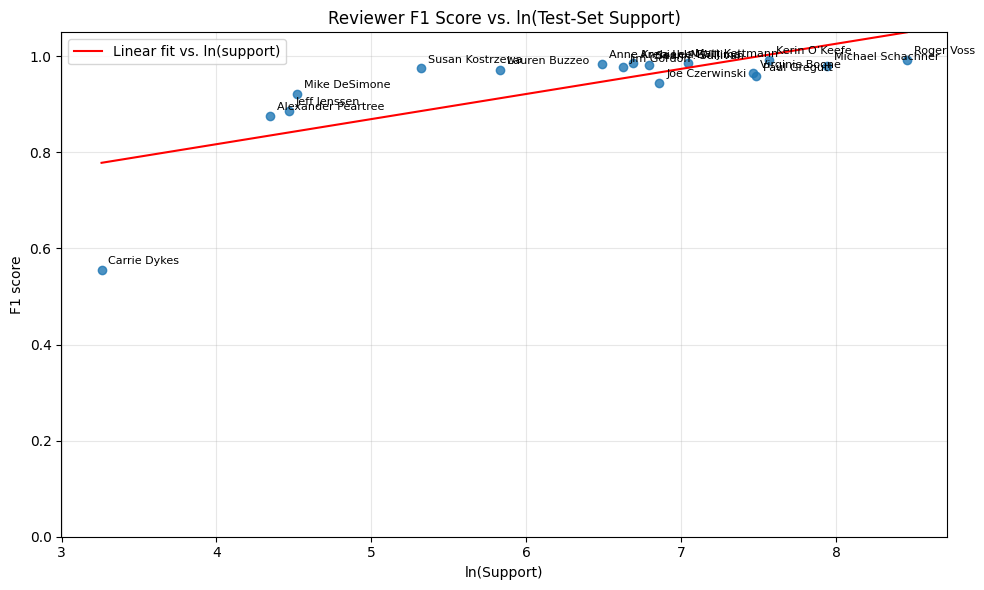

In [30]:
import matplotlib.pyplot as plt

plot_data = by_reviewer.dropna(subset=["support", "f1-score"]).copy()
plot_data = plot_data[plot_data["support"] > 0]
plot_data["ln_support"] = np.log(plot_data["support"])

# Linear fit against ln(support)
slope, intercept = np.polyfit(
    plot_data["ln_support"],
    plot_data["f1-score"],
    1
)

x_line = np.linspace(
    plot_data["ln_support"].min(),
    plot_data["ln_support"].max(),
    100
)
y_line = slope * x_line + intercept

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    plot_data["ln_support"],
    plot_data["f1-score"],
    alpha=0.8
)
ax.plot(
    x_line,
    y_line,
    color="red",
    label="Linear fit vs. ln(support)"
)

for reviewer, row in plot_data.iterrows():
    ax.annotate(
        reviewer,
        (row["ln_support"], row["f1-score"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("ln(Support)")
ax.set_ylabel("F1 score")
ax.set_title("Reviewer F1 Score vs. ln(Test-Set Support)")
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

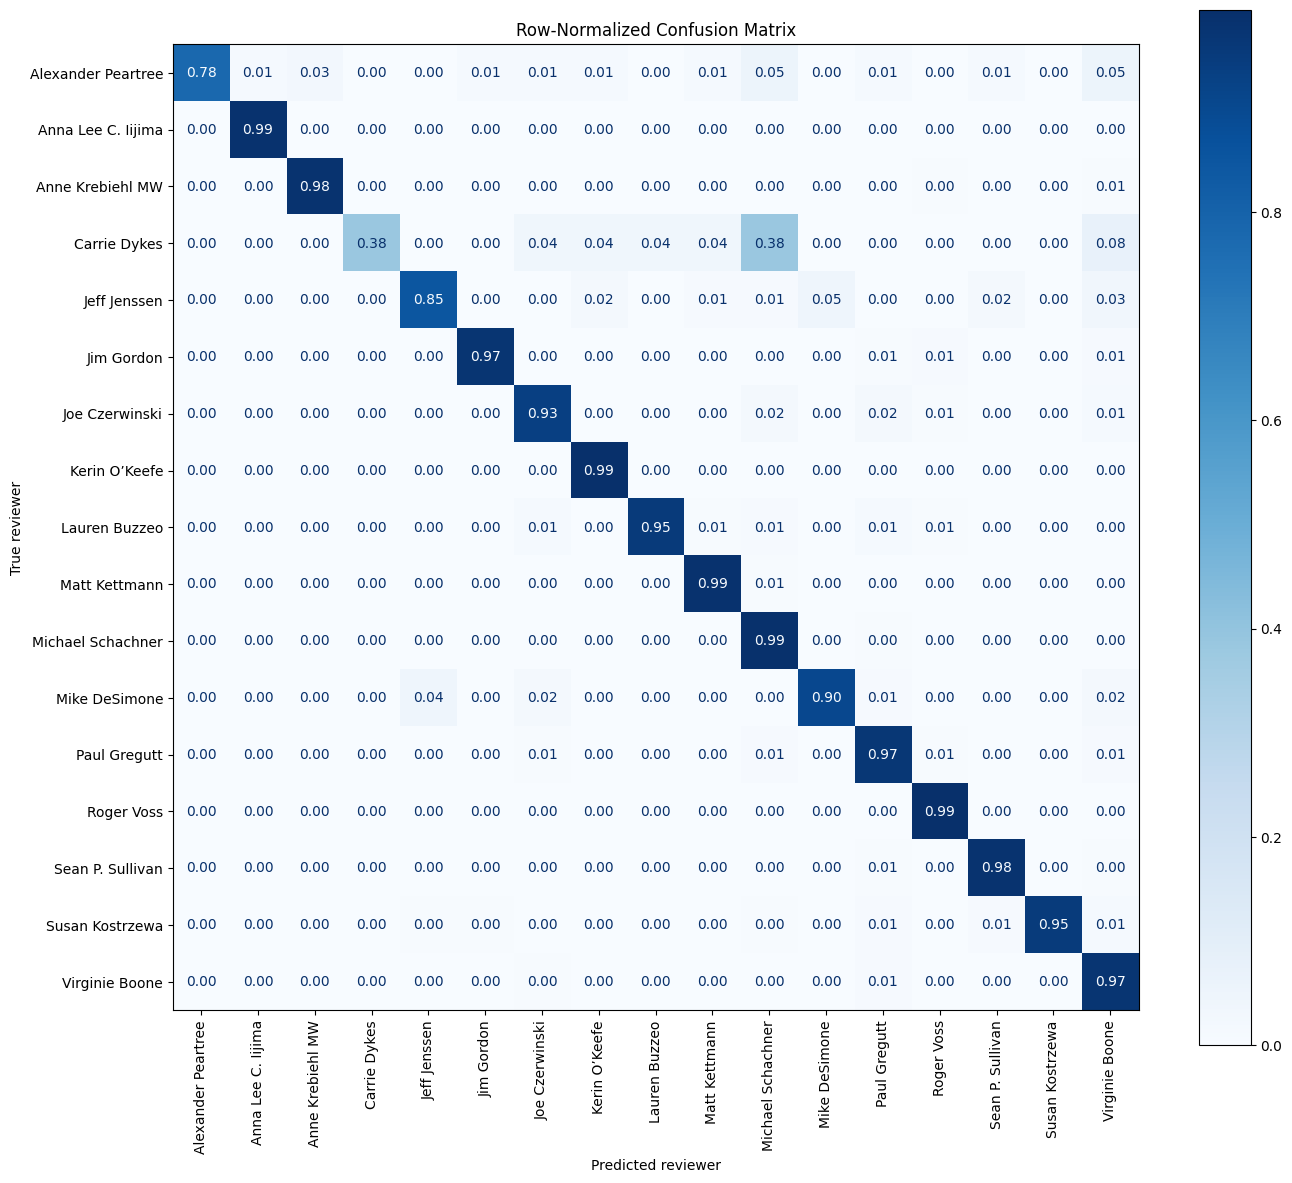

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

labels = label_encoder.classes_

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicted_reviewers,
    labels=labels,
    display_labels=labels,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=90,
    ax=ax
)

ax.set_title("Row-Normalized Confusion Matrix")
ax.set_xlabel("Predicted reviewer")
ax.set_ylabel("True reviewer")

plt.tight_layout()
plt.show()

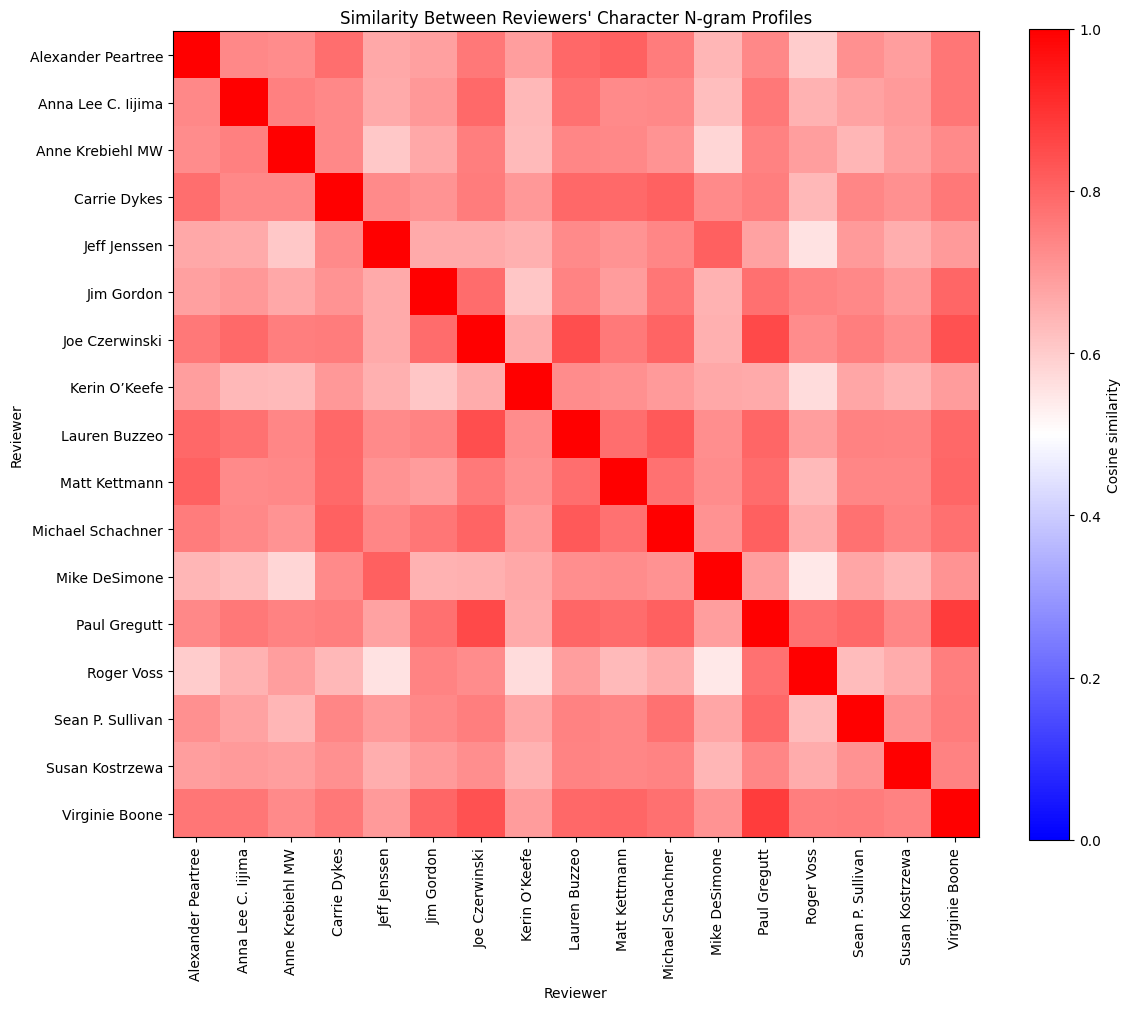

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

reviewer_names = label_encoder.classes_
y_train_array = y_train.to_numpy()

# X_fit_final contains character n-gram features followed by style features.
# Keep only the character n-gram portion for this comparison.
n_style_features = len(style_features(X_train.iloc[0]))
X_char_train = X_fit_final[:, :-n_style_features]

# Average character n-gram profile for each reviewer
reviewer_profiles = np.vstack([
    np.asarray(
        X_char_train[y_train_array == reviewer].mean(axis=0)
    ).ravel()
    for reviewer in reviewer_names
])

similarity = cosine_similarity(reviewer_profiles)

fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(similarity, cmap="bwr", vmin=0, vmax=1)

ax.set_xticks(range(len(reviewer_names)))
ax.set_xticklabels(reviewer_names, rotation=90)
ax.set_yticks(range(len(reviewer_names)))
ax.set_yticklabels(reviewer_names)

ax.set_title("Similarity Between Reviewers' Character N-gram Profiles")
ax.set_xlabel("Reviewer")
ax.set_ylabel("Reviewer")

fig.colorbar(image, ax=ax, label="Cosine similarity")
plt.tight_layout()
plt.show()